# Bài 1.1 - Pipeline tối ưu kết hợp: KD → Pruning → Quantization (CIFAR-10)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/KuSenpai/modelopt101/blob/exercise-1.1-pipeline-cifar10/exercises/1.1_pipeline_cifar10.ipynb)

**Mục tiêu.** Ghép ba kỹ thuật đã học ở notebook 01–03 thành **một pipeline** và đo xem sai số
cộng dồn ra sao qua từng bước:

```
ResNet-18 (teacher, FP32)
   └─ KD ──────────► student CNN nhỏ        (notebook 02)
        └─ structured prune 50% + fine-tune (notebook 03, fine-tune bằng KD loss)
             └─ PTQ INT8 per-channel        (notebook 01)
```

**Vì sao CIFAR-10 thay vì MNIST:** MNIST quá dễ (baseline 99%+) nên mọi kỹ thuật trông như
"không mất gì". CIFAR-10 đủ khó để thấy rõ cái giá của từng bước.

**Chỉ tiêu cần đạt** (so với teacher):

| chỉ tiêu | ngưỡng |
|----------|--------|
| kích thước trên đĩa | nhỏ hơn **≥ 10x** |
| accuracy | giảm **≤ 2%** |

Sau **mỗi bước** đều ghi lại params, size, accuracy, CPU latency vào một bảng chung.

**Runtime:** `Runtime -> Change runtime type -> GPU (T4)`, rồi `Runtime -> Run all`. Khoảng 30 phút.

## 1. Setup

In [1]:
import io, time, copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
import torchvision
import torchvision.transforms as T
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = device.type == "cuda"     # mixed precision: ~2x faster training on T4
print("device:", torch.cuda.get_device_name(0) if USE_AMP else "cpu")

# --- knobs you can play with ---
EPOCHS_TEACHER  = 15
EPOCHS_STUDENT  = 20
FINETUNE_EPOCHS = 5
BATCH_SIZE      = 256
LR              = 0.1
T_KD, ALPHA_KD  = 4.0, 0.7    # distillation temperature / weight on the teacher term
PRUNE_RATIO     = 0.5         # fraction of filters removed per conv layer
N_BITS          = 8           # weight quantization bit-width

device: Tesla T4


## 2. Data - CIFAR-10

10 lớp ảnh màu 32×32 (máy bay, ô tô, chim, mèo...). 50k train / 10k test.
Augmentation chuẩn: random crop có padding + lật ngang.

In [2]:
mean, std = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
                      T.ToTensor(), T.Normalize(mean, std)])
test_tf  = T.Compose([T.ToTensor(), T.Normalize(mean, std)])

train_set = torchvision.datasets.CIFAR10("./data", train=True,  download=True, transform=train_tf)
test_set  = torchvision.datasets.CIFAR10("./data", train=False, download=True, transform=test_tf)

train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2,
                          pin_memory=True, drop_last=True)
test_loader  = DataLoader(test_set,  batch_size=512,        shuffle=False, num_workers=2,
                          pin_memory=True)
print(len(train_set), "train /", len(test_set), "test images")

100%|██████████| 170M/170M [23:32<00:00, 121kB/s]


50000 train / 10000 test images


## 3. Models

- **Teacher:** ResNet-18 (11M params), bản CIFAR: conv đầu 3×3 stride 1, bỏ maxpool để không
  làm mất độ phân giải của ảnh 32×32.
- **Student:** CNN kiểu VGG giống notebook 03 (độ rộng kênh là tham số, để structured pruning
  dựng lại được bản hẹp hơn), đổi đầu vào sang 3 kênh màu.

In [3]:
def make_teacher(num_classes=10):
    m = torchvision.models.resnet18(num_classes=num_classes)
    m.conv1 = nn.Conv2d(3, 64, 3, stride=1, padding=1, bias=False)   # CIFAR stem
    m.maxpool = nn.Identity()
    return m

def conv_block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False),
                         nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class Net(nn.Module):
    def __init__(self, widths=(64, 64, 128, 128, 256, 256), num_classes=10):
        super().__init__()
        w = widths
        self.features = nn.Sequential(
            conv_block(3,    w[0]), conv_block(w[0], w[1]), nn.MaxPool2d(2),   # 32 -> 16
            conv_block(w[1], w[2]), conv_block(w[2], w[3]), nn.MaxPool2d(2),   # 16 -> 8
            conv_block(w[3], w[4]), conv_block(w[4], w[5]), nn.MaxPool2d(2),   # 8  -> 4
        )
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(w[5], num_classes))
        self.widths = tuple(widths)

    def forward(self, x):
        return self.head(self.features(x))

CONV_IDX = [0, 1, 3, 4, 6, 7]        # conv blocks inside `features` (the rest are MaxPool)
def conv_blocks(model):
    return [model.features[i] for i in CONV_IDX]

def count_params(m):
    return sum(p.numel() for p in m.parameters())

print(f"teacher params: {count_params(make_teacher()):,}")
print(f"student params: {count_params(Net()):,}")

teacher params: 11,173,962
student params: 1,148,874


## 4. Train / eval / metric utilities

`train` dùng SGD + OneCycle LR + mixed precision. `loss_fn(out, x, y)` giống notebook 02 để dùng
chung cho train thường và train có KD. Mọi model đi qua pipeline đều được `record` vào bảng `log`.

In [4]:
def train(model, loss_fn, epochs, lr=LR, tag=""):
    model.to(device).train()
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, nesterov=True, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, epochs=epochs,
                                                steps_per_epoch=len(train_loader))
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    for ep in range(epochs):
        t0 = time.time()
        for x, y in train_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device.type, enabled=USE_AMP):
                loss = loss_fn(model(x), x, y)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
        print(f"[{tag}] epoch {ep+1:02d}/{epochs}  test_acc={evaluate(model):.2f}%  ({time.time()-t0:.0f}s)")
    return model

@torch.no_grad()
def evaluate(model):
    model.to(device).eval()
    correct = total = 0
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        correct += (model(x).argmax(1) == y).sum().item()
        total += y.numel()
    model.train()
    return 100.0 * correct / total

@torch.no_grad()
def latency_ms(model, n=100):
    """Average single-image inference latency on CPU (ms)."""
    model = copy.deepcopy(model).to("cpu").eval()
    x = torch.randn(1, 3, 32, 32)
    for _ in range(10):
        model(x)
    t0 = time.time()
    for _ in range(n):
        model(x)
    return (time.time() - t0) / n * 1000.0

def model_size_mb(state_dict):
    buf = io.BytesIO()
    torch.save(state_dict, buf)
    return buf.getbuffer().nbytes / 1e6

log = []
def record(name, model, acc, size_mb=None):
    row = {"name": name, "params": count_params(model), "acc": acc,
           "size": size_mb if size_mb is not None else model_size_mb(model.state_dict()),
           "lat": latency_ms(model)}
    log.append(row)
    print(f">>> {name}: acc={acc:.2f}%  size={row['size']:.2f}MB  cpu={row['lat']:.2f}ms")

ce_loss = lambda out, x, y: F.cross_entropy(out, y)

## 5. Bước 0 - Train teacher (ResNet-18)

In [5]:
teacher = train(make_teacher(), ce_loss, EPOCHS_TEACHER, tag="teacher")
teacher_acc = evaluate(teacher)
record("0. teacher ResNet-18", teacher, teacher_acc)

[teacher] epoch 01/15  test_acc=48.39%  (27s)
[teacher] epoch 02/15  test_acc=59.47%  (25s)
[teacher] epoch 03/15  test_acc=71.07%  (24s)
[teacher] epoch 04/15  test_acc=76.15%  (24s)
[teacher] epoch 05/15  test_acc=78.14%  (25s)
[teacher] epoch 06/15  test_acc=79.55%  (26s)
[teacher] epoch 07/15  test_acc=79.07%  (25s)
[teacher] epoch 08/15  test_acc=83.89%  (25s)
[teacher] epoch 09/15  test_acc=84.99%  (24s)
[teacher] epoch 10/15  test_acc=85.67%  (25s)
[teacher] epoch 11/15  test_acc=85.58%  (25s)
[teacher] epoch 12/15  test_acc=88.04%  (25s)
[teacher] epoch 13/15  test_acc=90.42%  (25s)
[teacher] epoch 14/15  test_acc=90.85%  (25s)
[teacher] epoch 15/15  test_acc=91.20%  (24s)
>>> 0. teacher ResNet-18: acc=91.20%  size=44.77MB  cpu=20.45ms


## 6. Bước 1 - Student: không KD vs. có KD

Cùng kiến trúc, cùng số epoch. Khác nhau duy nhất ở loss (công thức từ notebook 02):

$$\mathcal{L} = \alpha T^2\,\mathrm{KL}\big(\sigma(z_s/T)\,\|\,\sigma(z_t/T)\big) + (1-\alpha)\,\mathrm{CE}(z_s, y)$$

In [6]:
def distillation_loss(student_logits, teacher_logits, labels, T=T_KD, alpha=ALPHA_KD):
    ce_term = F.cross_entropy(student_logits, labels)
    kd_term = F.kl_div(F.log_softmax(student_logits.float() / T, dim=1),
                       F.softmax(teacher_logits.float() / T, dim=1),
                       reduction="batchmean") * T ** 2
    return alpha * kd_term + (1 - alpha) * ce_term

teacher.eval()
for p in teacher.parameters():
    p.requires_grad_(False)

def kd_loss_fn(student_out, x, y):
    with torch.no_grad():
        teacher_out = teacher(x)
    return distillation_loss(student_out, teacher_out, y)

student_nokd = train(Net(), ce_loss, EPOCHS_STUDENT, tag="student-noKD")
record("1a. student, no KD", student_nokd, evaluate(student_nokd))

student_kd = train(Net(), kd_loss_fn, EPOCHS_STUDENT, tag="student-KD")
record("1b. student, KD", student_kd, evaluate(student_kd))

[student-noKD] epoch 01/20  test_acc=57.05%  (21s)
[student-noKD] epoch 02/20  test_acc=60.02%  (19s)
[student-noKD] epoch 03/20  test_acc=71.50%  (20s)
[student-noKD] epoch 04/20  test_acc=72.09%  (19s)
[student-noKD] epoch 05/20  test_acc=75.33%  (20s)
[student-noKD] epoch 06/20  test_acc=76.66%  (20s)
[student-noKD] epoch 07/20  test_acc=75.44%  (20s)
[student-noKD] epoch 08/20  test_acc=80.77%  (21s)
[student-noKD] epoch 09/20  test_acc=82.21%  (20s)
[student-noKD] epoch 10/20  test_acc=83.15%  (20s)
[student-noKD] epoch 11/20  test_acc=85.00%  (20s)
[student-noKD] epoch 12/20  test_acc=82.42%  (20s)
[student-noKD] epoch 13/20  test_acc=84.14%  (20s)
[student-noKD] epoch 14/20  test_acc=84.54%  (20s)
[student-noKD] epoch 15/20  test_acc=86.51%  (20s)
[student-noKD] epoch 16/20  test_acc=88.83%  (21s)
[student-noKD] epoch 17/20  test_acc=89.16%  (20s)
[student-noKD] epoch 18/20  test_acc=90.49%  (21s)
[student-noKD] epoch 19/20  test_acc=90.79%  (19s)
[student-noKD] epoch 20/20  tes

## 7. Bước 2 - Structured pruning + fine-tune bằng KD

Cắt `PRUNE_RATIO` filter có L1 nhỏ nhất ở mỗi lớp conv rồi dựng lại một `Net` hẹp hơn (notebook 03).
Khác notebook 03: **fine-tune bằng KD loss** - teacher giúp model đã cắt phục hồi nhanh hơn chỉ dùng nhãn.

In [7]:
def structured_prune(model, ratio):
    """L1-norm filter pruning -> a smaller Net with the kept filters copied in."""
    model = model.cpu()
    blocks = conv_blocks(model)
    keep = []
    for blk in blocks:
        k = max(1, round(blk[0].weight.shape[0] * (1 - ratio)))
        l1 = blk[0].weight.data.abs().sum(dim=(1, 2, 3))
        keep.append(torch.topk(l1, k).indices.sort().values)

    new = Net(widths=tuple(len(k) for k in keep)).eval()
    prev = torch.arange(3)                               # RGB input channels
    for ob, nb, idx in zip(blocks, conv_blocks(new), keep):
        nb[0].weight.data  = ob[0].weight.data[idx][:, prev, :, :].clone()
        nb[1].weight.data  = ob[1].weight.data[idx].clone()
        nb[1].bias.data    = ob[1].bias.data[idx].clone()
        nb[1].running_mean = ob[1].running_mean[idx].clone()
        nb[1].running_var  = ob[1].running_var[idx].clone()
        prev = idx
    new.head[2].weight.data = model.head[2].weight.data[:, prev].clone()
    new.head[2].bias.data   = model.head[2].bias.data.clone()
    return new

pruned = structured_prune(student_kd, PRUNE_RATIO)
print(f"widths {student_kd.widths} -> {pruned.widths}")
record("2a. pruned (no fine-tune)", pruned, evaluate(pruned))

pruned = train(pruned, kd_loss_fn, FINETUNE_EPOCHS, lr=LR * 0.2, tag="finetune-KD")
record("2b. pruned + KD fine-tune", pruned, evaluate(pruned))

widths (64, 64, 128, 128, 256, 256) -> (32, 32, 64, 64, 128, 128)
>>> 2a. pruned (no fine-tune): acc=14.38%  size=1.17MB  cpu=2.57ms
[finetune-KD] epoch 01/5  test_acc=82.98%  (21s)
[finetune-KD] epoch 02/5  test_acc=85.26%  (20s)
[finetune-KD] epoch 03/5  test_acc=86.33%  (21s)
[finetune-KD] epoch 04/5  test_acc=88.64%  (20s)
[finetune-KD] epoch 05/5  test_acc=89.49%  (21s)
>>> 2b. pruned + KD fine-tune: acc=89.49%  size=1.17MB  cpu=2.45ms


## 8. Bước 3 - PTQ INT8 (weight-only, symmetric, per-channel)

Dùng lại `quantize` / `dequantize` từ notebook 01. Size đo trên bản **packed** (int8 + scale),
accuracy đo trên bản **fake-quant**. Latency không đổi vì vẫn chạy kernel FP32 (xem notebook 01).

In [8]:
def quantize(x, n_bits=8, symmetric=True, per_channel=False):
    qmin, qmax = -(2 ** (n_bits - 1)), 2 ** (n_bits - 1) - 1
    if per_channel:
        flat = x.flatten(1)
        xmin, xmax = flat.min(1).values, flat.max(1).values
    else:
        xmin, xmax = x.min(), x.max()
    if symmetric:
        scale = (torch.maximum(xmin.abs(), xmax.abs()) / qmax).clamp(min=1e-8)
        zero_point = torch.zeros_like(scale)
    else:
        scale = ((xmax - xmin) / (qmax - qmin)).clamp(min=1e-8)
        zero_point = qmin - torch.round(xmin / scale)
    shape = [-1] + [1] * (x.dim() - 1)
    s = scale.view(shape) if per_channel else scale
    z = zero_point.view(shape) if per_channel else zero_point
    q = torch.clamp(torch.round(x / s) + z, qmin, qmax)
    return q, scale, zero_point

def dequantize(q, scale, zero_point, per_channel=False):
    if per_channel:
        shape = [-1] + [1] * (q.dim() - 1)
        scale, zero_point = scale.view(shape), zero_point.view(shape)
    return scale * (q - zero_point)

QUANTIZABLE = (nn.Conv2d, nn.Linear)

def quantize_model(model, n_bits=8, per_channel=True):
    """Return (packed_state_dict, dequantized_model) for weight-only PTQ."""
    packed = {}
    deq = copy.deepcopy(model).cpu().eval()
    qnames = [n for n, m in deq.named_modules() if isinstance(m, QUANTIZABLE)]
    for name, mod in deq.named_modules():
        if isinstance(mod, QUANTIZABLE):
            q, s, z = quantize(mod.weight.data, n_bits=n_bits, per_channel=per_channel)
            packed[name + ".weight_int"]   = q.to(torch.int8)
            packed[name + ".weight_scale"] = s.clone()
            mod.weight.data = dequantize(q, s, z, per_channel=per_channel)
    for k, v in deq.state_dict().items():
        if k not in {n + ".weight" for n in qnames}:
            packed[k] = v
    return packed, deq

packed, final_model = quantize_model(pruned, n_bits=N_BITS)
record(f"3. + PTQ INT{N_BITS}", final_model, evaluate(final_model), size_mb=model_size_mb(packed))

# bonus: how far can the bit-width go on this already-pruned model?
for b in (6, 4, 3):
    print(f"   INT{b} per-channel accuracy: {evaluate(quantize_model(pruned, n_bits=b)[1]):.2f}%")

>>> 3. + PTQ INT8: acc=89.51%  size=0.31MB  cpu=2.55ms
   INT6 per-channel accuracy: 89.36%
   INT4 per-channel accuracy: 85.85%
   INT3 per-channel accuracy: 79.26%


## 9. Kết quả - bảng sau từng bước

step                             params      size  x smaller      acc    Δacc   CPU lat
---------------------------------------------------------------------------------------
0. teacher ResNet-18         11,173,962   44.77MB       1.0x   91.20%   +0.00   20.45ms
1a. student, no KD            1,148,874    4.62MB       9.7x   90.63%   -0.57    5.68ms
1b. student, KD               1,148,874    4.62MB       9.7x   91.38%   +0.18    5.61ms
2a. pruned (no fine-tune)       288,746    1.17MB      38.2x   14.38%  -76.82    2.57ms
2b. pruned + KD fine-tune       288,746    1.17MB      38.2x   89.49%   -1.71    2.45ms
3. + PTQ INT8                   288,746    0.31MB     144.4x   89.51%   -1.69    2.55ms

final vs teacher: 144.4x smaller, accuracy -1.69%
target >=10x smaller : PASS
target <=2% acc drop : PASS


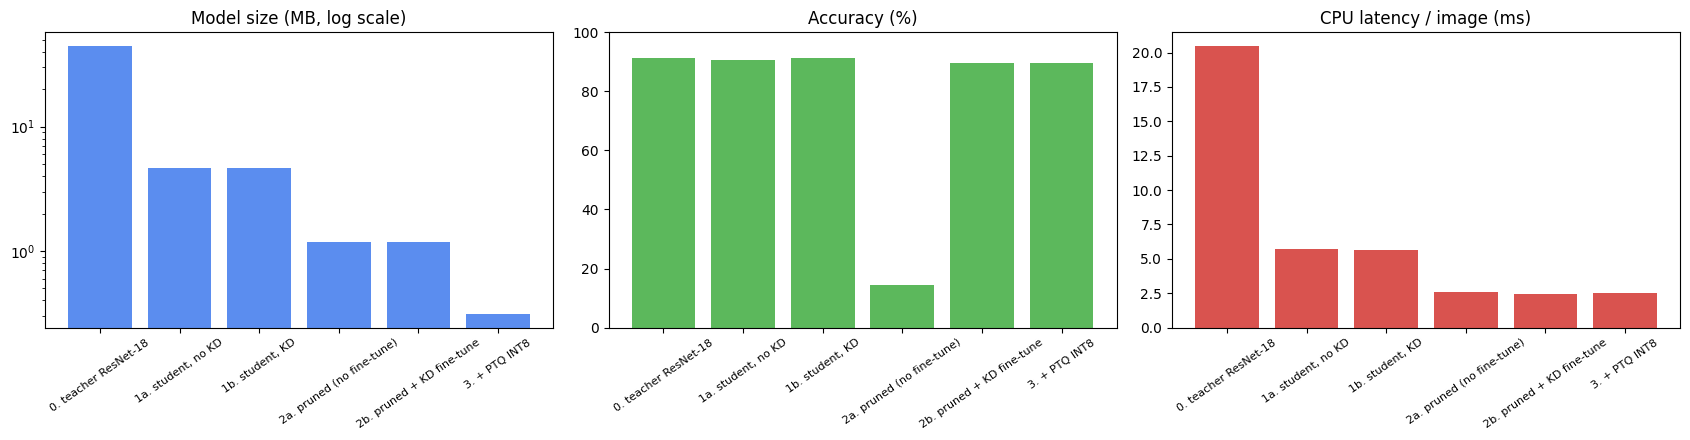

In [9]:
t = log[0]
print(f"{'step':<28}{'params':>11}{'size':>10}{'x smaller':>11}{'acc':>9}{'Δacc':>8}{'CPU lat':>10}")
print("-" * 87)
for r in log:
    print(f"{r['name']:<28}{r['params']:>11,}{r['size']:>8.2f}MB{t['size']/r['size']:>10.1f}x"
          f"{r['acc']:>8.2f}%{r['acc']-t['acc']:>+8.2f}{r['lat']:>8.2f}ms")

final = log[-1]
ratio, drop = t["size"] / final["size"], t["acc"] - final["acc"]
print(f"\nfinal vs teacher: {ratio:.1f}x smaller, accuracy {-drop:+.2f}%")
print(f"target >=10x smaller : {'PASS' if ratio >= 10 else 'FAIL'}")
print(f"target <=2% acc drop : {'PASS' if drop <= 2 else 'FAIL'}")

names = [r["name"] for r in log]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].bar(names, [r["size"] for r in log], color="#5b8def"); ax[0].set_yscale("log")
ax[0].set_title("Model size (MB, log scale)")
ax[1].bar(names, [r["acc"] for r in log], color="#5cb85c")
ax[1].set_ylim(0, 100); ax[1].set_title("Accuracy (%)")
ax[2].bar(names, [r["lat"] for r in log], color="#d9534f"); ax[2].set_title("CPU latency / image (ms)")
for a in ax: a.tick_params(axis="x", rotation=35, labelsize=8)
plt.tight_layout(); plt.show()

## 10. Nhận xét

*Kết quả một lần chạy trên Colab Tesla T4 (một seed), các knob giữ mặc định.*

**1. Bước nào mất accuracy nhiều nhất? Bước nào gần như "miễn phí"?**
- Cắt filter là bước đắt nhất. Ngay sau khi cắt 50% filter, accuracy rơi từ 91.38% xuống **14.38%**, gần mức đoán ngẫu nhiên. Sau khi fine-tune, bước pruning vẫn là bước duy nhất mất accuracy đáng kể: 91.38% → 89.49% (**−1.89 điểm**), đổi lại model nhỏ đi 4x (4.62 → 1.17 MB) và chỉ còn 288,746 params.
- PTQ INT8 gần như miễn phí: 89.49% → 89.51% (+0.02, nằm trong nhiễu) mà size giảm thêm 3.8x (1.17 → 0.31 MB). INT6 cũng gần như không mất gì (89.36%). Bắt đầu đau từ INT4 (85.85%, −3.6 điểm) và INT3 (79.26%).
- Bước KD (ResNet-18 → student VGG) cũng "miễn phí": nhỏ hơn 9.7x mà accuracy còn nhỉnh hơn teacher (+0.18).

**2. KD giúp student được bao nhiêu so với không KD?**
Cùng kiến trúc, cùng 20 epoch: có KD đạt **91.38%**, không KD đạt **90.63%**, tức KD hơn **+0.75 điểm**. Có KD thì student vượt teacher (91.20%), không KD thì thấp hơn teacher 0.57. KD cũng giúp học nhanh hơn ở các epoch đầu: epoch 2 đạt 74.81% so với 60.02%, epoch 6 đạt 85.27% so với 76.66%.

**3. Fine-tune bằng KD phục hồi được bao nhiêu sau khi cắt filter?**
Từ 14.38% lên **89.49%** sau 5 epoch (**+75.11 điểm**). Chỉ sau 1 epoch đã lên 82.98%. Model sau khi cắt chỉ còn kém student chưa cắt 1.89 điểm. Đến epoch cuối accuracy vẫn đang tăng (88.64 → 89.49), nghĩa là fine-tune chưa bão hoà.

**4. Có đạt cả hai chỉ tiêu không? Nếu chưa, nên chỉnh knob nào?**
**Đạt cả hai:** nhỏ hơn **144.4x** (chỉ tiêu ≥ 10x) và accuracy giảm **1.69 điểm** (chỉ tiêu ≤ 2). Tuy vậy, biên an toàn về accuracy khá mỏng, chỉ còn 0.31 điểm, chưa chắc giữ được nếu đổi seed. Muốn chắc hơn thì:
- Tăng `FINETUNE_EPOCHS` (ví dụ 10): accuracy vẫn còn đang lên ở epoch 5.
- Giảm `PRUNE_RATIO` xuống 0.3–0.4: size đang dư rất xa chỉ tiêu (144x so với 10x), có thể đổi bớt độ nén lấy accuracy.
- Lưu ý: teacher chỉ train 15 epoch (91.20%). Nếu train teacher lâu hơn thì teacher giỏi hơn, khi đó mức giảm so với teacher có thể tăng chứ không giảm.
- Không nên hạ xuống INT4: sẽ mất ~5.3 điểm so với teacher, trượt chỉ tiêu.

**5. Vì sao CPU latency giảm ở bước pruning nhưng không giảm ở bước INT8?**
- Structured pruning bỏ hẳn filter, nên model thật sự hẹp hơn: ít kênh hơn, ít FLOPs hơn, vẫn chạy bằng kernel FP32 dày. Vì vậy latency giảm từ 5.61 ms xuống ~2.5 ms.
- PTQ ở đây chỉ là weight-only fake-quant: weight được làm tròn về lưới INT8 rồi dequantize ngược về FP32, và mạng vẫn chạy bằng đúng các kernel FP32 như trước. Phép tính không đổi nên latency không đổi (2.45 → 2.55 ms là nhiễu đo). INT8 chỉ giúp giảm size khi lưu dạng packed. Muốn nhanh hơn thì cần quantize cả activation và chạy bằng kernel số nguyên thật (ví dụ `torch.ao.quantization` với backend fbgemm/qnnpack, ONNX Runtime hoặc TensorRT).
